In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import numpy as np
from matplotlib import pyplot as plt
from numpy import array, nan, inf, float32  # noqa: F401

In [2]:
plots = Path("plots") / "quantiles"

In [3]:
from dataclasses import dataclass
from enum import StrEnum


@dataclass
class BitInformationBounds:
    percentile: list[float]
    keepbits: list[int]
    linquant_absolute: list[float]
    bitround_relative: list[float]


class ErrorKind(StrEnum):
    POINTWISE = "pointwise"
    MEAN = "mean"

    def __repr__(self) -> str:
        return f"{type(self).__name__}.{self._name_}"


@dataclass
class ExpertEnsembleSpreadQuantile:
    absolute: float
    absolute_value: float
    absolute_kind: ErrorKind
    relative: float
    relative_value: float
    relative_kind: ErrorKind


@dataclass
class EnsembleSpreadBounds:
    percentile: list[float]
    absolute: list[float]
    relative: list[float]
    quadratic: list[float]


@dataclass
class RangeBounds:
    min: float
    max: float
    min_abs: float

In [4]:
def parse_single(path: Path):
    with Path(path).open() as f:
        for line in f.readlines():
            var, rest = line.split(": ", 1)
            info = eval(rest)

            yield var, info

In [5]:
def parse_pressure(path: Path):
    with Path(path).open() as f:
        ls = iter(f.readlines())

        line = None

        while True:
            if line is None:
                try:
                    line = next(ls)
                except Exception:
                    break

            var, rest = line.split(":", 1)

            while True:
                try:
                    line = next(ls)
                except Exception:
                    line = None
                    break

                if len(line.strip()) == 0:
                    continue

                if not line.startswith(" - "):
                    break

                level, rest = line[len(" - ") :].split(": ", 1)
                info = eval(rest)

                yield var, level, info

In [6]:
single_expert = list(parse_single("expert-quantile-single.txt"))

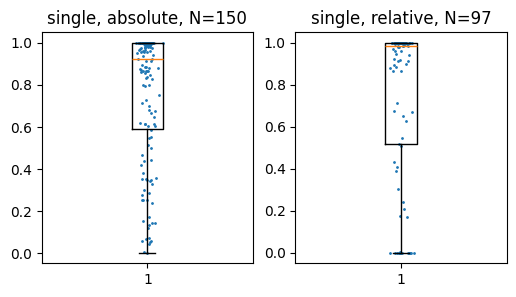

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

rng = np.random.default_rng(seed=42)

sabs = [q.absolute for v, q in single_expert if not np.isnan(q.absolute)]
srel = [q.relative for v, q in single_expert if not np.isnan(q.relative)]

ax1.boxplot(sabs)
ax1.scatter(rng.normal(loc=1, scale=0.025, size=len(sabs)), sabs, s=1)
ax1.set_title(f"single, absolute, N={len(sabs)}")
ax2.boxplot(srel)
ax2.scatter(rng.normal(loc=1, scale=0.025, size=len(srel)), srel, s=1)
ax2.set_title(f"single, relative, N={len(srel)}")

plt.show()
fig.savefig(plots / "single-boxplot.pdf")

In [8]:
pressure_expert = list(parse_pressure("expert-quantile-pressure.txt"))

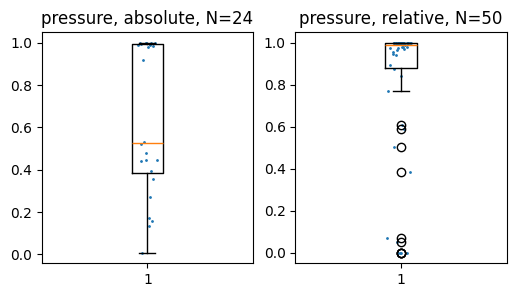

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3))

rng = np.random.default_rng(seed=24)

sabs = [q.absolute for v, p, q in pressure_expert if not np.isnan(q.absolute)]
srel = [q.relative for v, p, q in pressure_expert if not np.isnan(q.relative)]

ax1.boxplot(sabs)
ax1.scatter(rng.normal(loc=1, scale=0.025, size=len(sabs)), sabs, s=1)
ax1.set_title(f"pressure, absolute, N={len(sabs)}")
ax2.boxplot(srel)
ax2.scatter(rng.normal(loc=1, scale=0.025, size=len(srel)), srel, s=1)
ax2.set_title(f"pressure, relative, N={len(srel)}")

plt.show()
fig.savefig(plots / "pressure-boxplot.pdf")

In [10]:
single_ensemble = dict(parse_single("ensemble-spread-single.txt"))

In [11]:
single_range = dict(parse_single("range-single.txt"))

In [12]:
single_bit_information = dict(parse_single("bit-information-single.txt"))

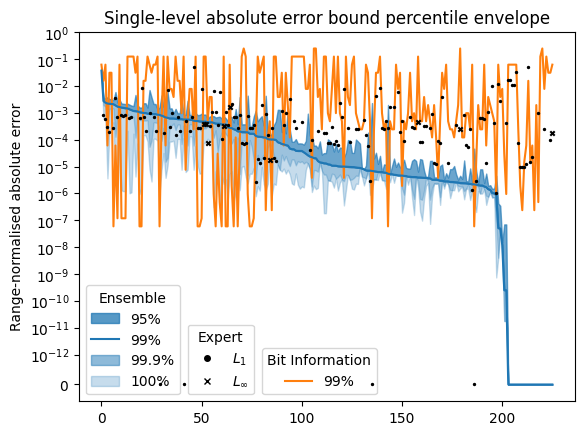

In [13]:
fig, ax = plt.subplots()

ax.set_title("Single-level absolute error bound percentile envelope")
ax.set_ylabel("Range-normalised absolute error")

scores = {
    v: (
        0.0
        if single_range[v].max == single_range[v].min
        else (e.absolute[2] / (single_range[v].max - single_range[v].min))
    )
    for v, e in single_ensemble.items()
}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

single_expert_dict = dict(single_expert)
expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(
        0.0
        if single_range[v].max == single_range[v].min
        else (
            single_expert_dict[v].absolute_value
            / (single_range[v].max - single_range[v].min)
        )
    )
    expert_pointwise.append(single_expert_dict[v].absolute_kind is ErrorKind.POINTWISE)
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

# ax.fill_between(
#     range(len(v_sorted)),
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[0]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[2]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     alpha=0.25,
#     color="tab:orange",
#     label="100%",
# )
# ax.fill_between(
#     range(len(v_sorted)),
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[1]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[2]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     alpha=0.25,
#     color="tab:orange",
#     label="99.9%",
# )
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_bit_information[v].linquant_absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:orange",
    label="99%",
)
# ax.fill_between(
#     range(len(v_sorted)),
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[3]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     [
#         (
#             0.0
#             if single_range[v].max == single_range[v].min
#             else (
#                 single_bit_information[v].linquant_absolute[2]
#                 / (single_range[v].max - single_range[v].min)
#             )
#         )
#         for v in v_sorted
#     ],
#     alpha=0.66,
#     color="tab:orange",
#     label="95%",
# )

ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[0]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:blue",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[1]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.25,
    color="tab:blue",
    label="99.9%",
)
ax.plot(
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    color="tab:blue",
    label="99%",
)
ax.fill_between(
    range(len(v_sorted)),
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[3]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    [
        (
            0.0
            if single_range[v].max == single_range[v].min
            else (
                single_ensemble[v].absolute[2]
                / (single_range[v].max - single_range[v].min)
            )
        )
        for v in v_sorted
    ],
    alpha=0.66,
    color="tab:blue",
    label="95%",
)

ax.set_yscale("symlog", linthresh=1e-12)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:blue", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:blue", label="99%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
ax.legend(
    handles=[
        # mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
        # mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
        # mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.355, 0, 1, 1),
    title="Bit Information",
)
ax.add_artist(l1)
ax.add_artist(l2)

plt.show()
fig.savefig(plots / "single-absolute.pdf")

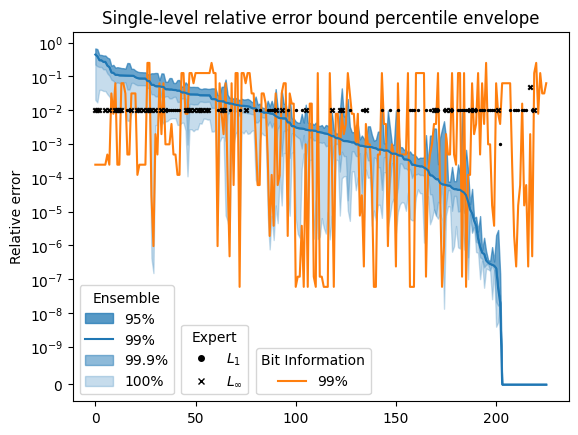

In [14]:
fig, ax = plt.subplots()

ax.set_title("Single-level relative error bound percentile envelope")
ax.set_ylabel("Relative error")

scores = {v: e.relative[2] for v, e in single_ensemble.items()}
v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

single_expert_dict = dict(single_expert)
expert_xs = []
expert_ys = []
expert_pointwise = []
for i, v in enumerate(v_sorted):
    expert_xs.append(i)
    expert_ys.append(single_expert_dict[v].relative_value)
    expert_pointwise.append(single_expert_dict[v].absolute_kind is ErrorKind.POINTWISE)
expert_pointwise = np.array(expert_pointwise)
ax.scatter(
    np.array(expert_xs)[expert_pointwise],
    np.array(expert_ys)[expert_pointwise],
    s=10,
    marker="x",
    c="black",
    label="expert",
    zorder=9,
)
ax.scatter(
    np.array(expert_xs)[~expert_pointwise],
    np.array(expert_ys)[~expert_pointwise],
    s=2,
    marker="o",
    c="black",
    label="expert",
    zorder=9,
)

# ax.fill_between(
#     range(len(v_sorted)),
#     [single_bit_information[v].bitround_relative[0] for v in v_sorted],
#     [single_bit_information[v].bitround_relative[2] for v in v_sorted],
#     alpha=0.25,
#     color="tab:orange",
#     label="100%",
# )
# ax.fill_between(
#     range(len(v_sorted)),
#     [single_bit_information[v].bitround_relative[1] for v in v_sorted],
#     [single_bit_information[v].bitround_relative[2] for v in v_sorted],
#     alpha=0.25,
#     color="tab:orange",
#     label="99.9%",
# )
ax.plot(
    [single_bit_information[v].bitround_relative[2] for v in v_sorted],
    color="tab:orange",
    label="99%",
)
# ax.fill_between(
#     range(len(v_sorted)),
#     [single_bit_information[v].bitround_relative[3] for v in v_sorted],
#     [single_bit_information[v].bitround_relative[2] for v in v_sorted],
#     alpha=0.66,
#     color="tab:orange",
#     label="95%",
# )

ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[0] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:blue",
    label="100%",
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[1] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.25,
    color="tab:blue",
    label="99.9%",
)
ax.plot(
    [single_ensemble[v].relative[2] for v in v_sorted], color="tab:blue", label="99%"
)
ax.fill_between(
    range(len(v_sorted)),
    [single_ensemble[v].relative[3] for v in v_sorted],
    [single_ensemble[v].relative[2] for v in v_sorted],
    alpha=0.66,
    color="tab:blue",
    label="95%",
)

ax.set_yscale("symlog", linthresh=1e-9)

l1 = ax.legend(
    handles=[
        mpl.patches.Patch(color="tab:blue", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:blue", label="99%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.5, label="99.9%"),
        mpl.patches.Patch(color="tab:blue", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    title="Ensemble",
)
l2 = ax.legend(
    handles=[
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="o",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label="$L_1$",
        ),
        mpl.lines.Line2D(
            [0],
            [0],
            markersize=4,
            marker="x",
            color="none",
            markerfacecolor="black",
            markeredgecolor="black",
            label=r"$L_{\infty}$",
        ),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.205, 0, 1, 1),
    title="Expert",
)
ax.legend(
    handles=[
        # mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
        mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
        # mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
        # mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
    ],
    ncol=1,
    loc="lower left",
    bbox_to_anchor=(0.355, 0, 1, 1),
    title="Bit Information",
)
ax.add_artist(l1)
ax.add_artist(l2)

plt.show()
fig.savefig(plots / "single-relative.pdf")

In [15]:
pressure_bit_information = defaultdict(dict)
for v, p, r in parse_pressure("bit-information-pressure.txt"):
    pressure_bit_information[p][v] = r

In [16]:
pressure_ensemble = defaultdict(dict)
for v, p, r in parse_pressure("ensemble-spread-pressure.txt"):
    pressure_ensemble[p][v] = r

In [17]:
pressure_range = defaultdict(dict)
for v, p, r in parse_pressure("range-pressure.txt"):
    pressure_range[p][v] = r

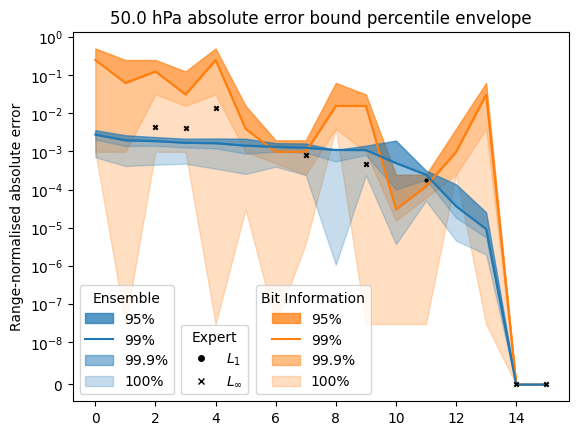

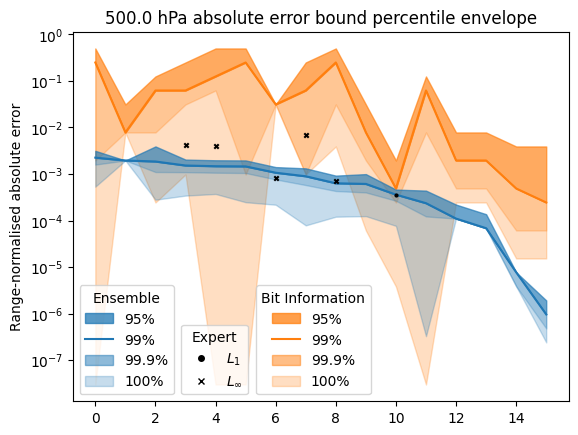

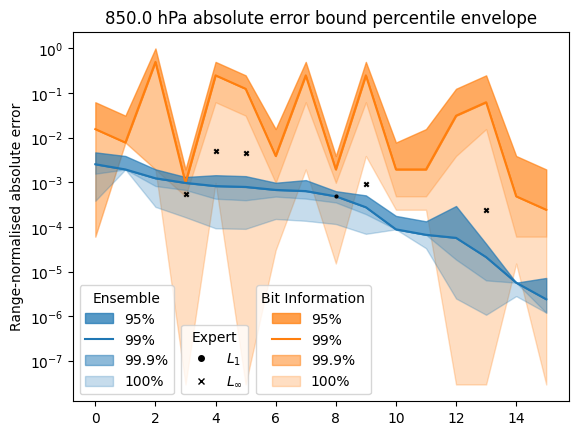

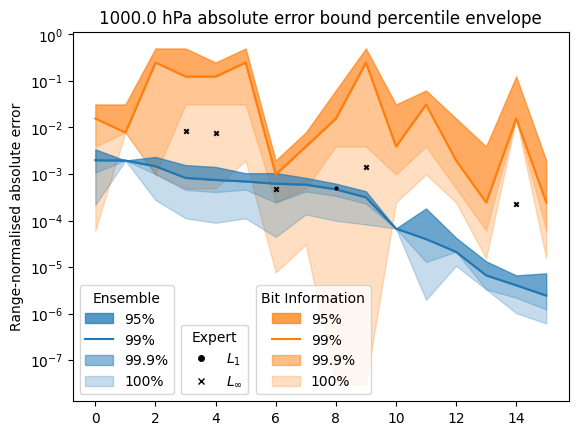

In [18]:
for p in pressure_ensemble.keys():
    fig, ax = plt.subplots()

    ax.set_title(f"{p} absolute error bound percentile envelope")
    ax.set_ylabel("Range-normalised absolute error")

    scores = {
        v: (
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (e.absolute[2] / (pressure_range[p][v].max - pressure_range[p][v].min))
        )
        for v, e in pressure_ensemble[p].items()
    }
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    pressure_expert_dict = defaultdict(dict)
    for v, p2, r in pressure_expert:
        pressure_expert_dict[p2][v] = r
    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(
            0.0
            if pressure_range[p][v].max == pressure_range[p][v].min
            else (
                pressure_expert_dict[p][v].absolute_value
                / (pressure_range[p][v].max - pressure_range[p][v].min)
            )
        )
        expert_pointwise.append(
            pressure_expert_dict[p][v].absolute_kind is ErrorKind.POINTWISE
        )
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:orange",
        label="BI-100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:orange",
        label="BI-99.9%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:orange",
        label="BI-99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_bit_information[p][v].linquant_absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:orange",
        label="BI-95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[0]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:blue",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[1]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.25,
        color="tab:blue",
        label="99.9%",
    )
    ax.plot(
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        color="tab:blue",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[3]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        [
            (
                0.0
                if pressure_range[p][v].max == pressure_range[p][v].min
                else (
                    pressure_ensemble[p][v].absolute[2]
                    / (pressure_range[p][v].max - pressure_range[p][v].min)
                )
            )
            for v in v_sorted
        ],
        alpha=0.66,
        color="tab:blue",
        label="95%",
    )

    ax.set_yscale("symlog", linthresh=1e-8)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:blue", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:blue", label="99%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.355, 0, 1, 1),
        title="Bit Information",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-absolute.pdf")

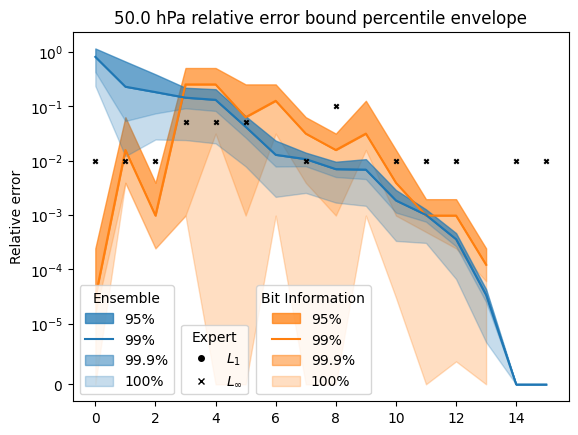

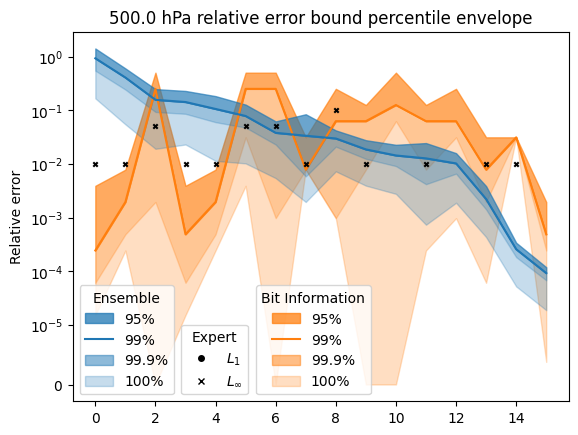

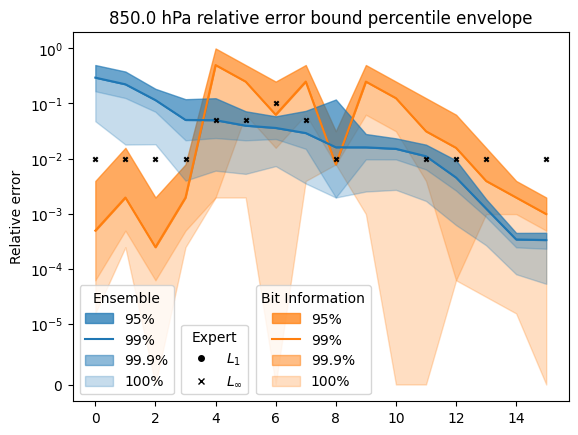

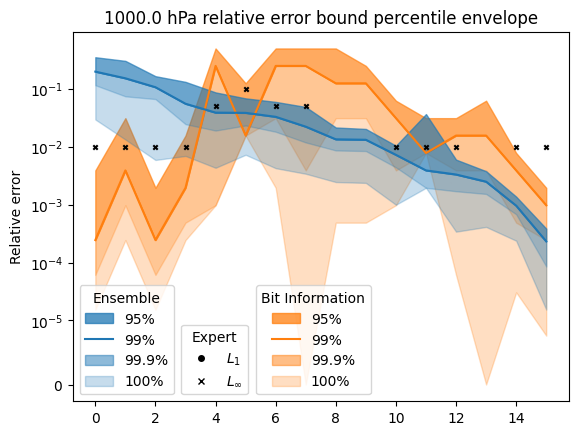

In [19]:
for p in pressure_ensemble.keys():
    fig, ax = plt.subplots()

    ax.set_title(f"{p} relative error bound percentile envelope")
    ax.set_ylabel("Relative error")

    scores = {v: e.relative[2] for v, e in pressure_ensemble[p].items()}
    v_sorted = sorted(scores.keys(), key=lambda k: scores[k], reverse=True)

    pressure_expert_dict = defaultdict(dict)
    for v, p2, r in pressure_expert:
        pressure_expert_dict[p2][v] = r
    expert_xs = []
    expert_ys = []
    expert_pointwise = []
    for i, v in enumerate(v_sorted):
        expert_xs.append(i)
        expert_ys.append(pressure_expert_dict[p][v].relative_value)
        expert_pointwise.append(
            pressure_expert_dict[p][v].absolute_kind is ErrorKind.POINTWISE
        )
    expert_pointwise = np.array(expert_pointwise)
    ax.scatter(
        np.array(expert_xs)[expert_pointwise],
        np.array(expert_ys)[expert_pointwise],
        s=10,
        marker="x",
        c="black",
        label="expert",
        zorder=9,
    )
    ax.scatter(
        np.array(expert_xs)[~expert_pointwise],
        np.array(expert_ys)[~expert_pointwise],
        s=4,
        marker="o",
        c="black",
        label="expert",
        zorder=9,
    )

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[0] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:orange",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[1] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:orange",
        label="99.9%",
    )
    ax.plot(
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        color="tab:orange",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_bit_information[p][v].bitround_relative[3] for v in v_sorted],
        [pressure_bit_information[p][v].bitround_relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:orange",
        label="95%",
    )

    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[0] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:blue",
        label="100%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[1] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.25,
        color="tab:blue",
        label="99.9%",
    )
    ax.plot(
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        color="tab:blue",
        label="99%",
    )
    ax.fill_between(
        range(len(v_sorted)),
        [pressure_ensemble[p][v].relative[3] for v in v_sorted],
        [pressure_ensemble[p][v].relative[2] for v in v_sorted],
        alpha=0.66,
        color="tab:blue",
        label="95%",
    )

    ax.set_yscale("symlog", linthresh=1e-5)

    l1 = ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:blue", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:blue", label="99%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:blue", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        title="Ensemble",
    )
    l2 = ax.legend(
        handles=[
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="o",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label="$L_1$",
            ),
            mpl.lines.Line2D(
                [0],
                [0],
                markersize=4,
                marker="x",
                color="none",
                markerfacecolor="black",
                markeredgecolor="black",
                label=r"$L_{\infty}$",
            ),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.205, 0, 1, 1),
        title="Expert",
    )
    ax.legend(
        handles=[
            mpl.patches.Patch(color="tab:orange", alpha=0.75, label="95%"),
            mpl.lines.Line2D([0], [0], color="tab:orange", label="99%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.5, label="99.9%"),
            mpl.patches.Patch(color="tab:orange", alpha=0.25, label="100%"),
        ],
        ncol=1,
        loc="lower left",
        bbox_to_anchor=(0.355, 0, 1, 1),
        title="Bit Information",
    )
    ax.add_artist(l1)
    ax.add_artist(l2)

    plt.show()
    fig.savefig(plots / f"pressure-{p.replace(' ', '')}-relative.pdf")